# Project 05: Who responds because of assignment?

This notebook explains an executed study, not an unrun model sketch. Run `python run.py` to download the publisher data and fit all nine estimators first. Results are released Criteo advertising benchmark contrasts, not original campaign effects or wireless retention. Read DATA_CARD and protocol before interpreting numbers.

In [1]:
from pathlib import Path
import json, pandas as pd, numpy as np
from IPython.display import display, Image
R=Path('results')
e=json.loads((R/'experiment.json').read_text())
e

Out[0]: 
{'seed': 20261123,
 'platform': 'Linux-6.18.57-x86_64-with-glibc2.41',
 'python': '3.12.14 (main, Aug 25 2026, 14:00:49) [Clang 22.1.3 ]',
 'selected_model': 'boosted_7',
 'train_assignment_share': 0.8504043396167129,
 'treatment_auc_test': 0.5087373879044244,
 'max_abs_training_smd': 0.04553405144304878,
 'min_test_propensity': 0.806399694754846,
 'max_test_propensity': 0.9130164112142239,
 'sample_rows': 699450,
 'test_rows': 210123,
 'test_profiles': 208459,
 'repeated_profile_rows': 11204,
 'fits': 9,
 'fit_explanation': '8 outcome fits + 1 assignment audit fit; no resampled model refitting',
 'scope': 'Released privacy-altered advertising benchmark; no original population ITT or telecom effect',
 'bootstrap_reps': 500,
 'protocol_sha256': '365a9eca6a2b2bebbb9f904106aae209d9827214556b28c5bef0f781d44ce3e4',
 'source_sha256': '2716e1bf0fd157a93b5bf86924d9088419dfbac2022c6cd90030220634f616dc',
 'seconds': 157.9}


## Audit before inference

Assignment is not exposure. Visit is the outcome. Anonymous baseline features are the only predictors. Nonuniform privacy selection prevents original-population effect recovery. We preserve profile groups across train/validation/test; source ordinals are not dates.

In [2]:
display(pd.read_csv(R/'audit.csv'))
display(pd.read_csv(R/'balance.csv'))
s=pd.read_csv(R/'splits.csv.gz')
assert s.groupby('profile').split.nunique().max()==1
print('No profile crosses a split boundary:', len(s), 'rows')

No profile crosses a split boundary: 699450 rows


,split,treatment,n,visits,rate,profiles
0,test,0,31048,1178,0.037941,31003
1,test,1,179075,8600,0.048025,177892
2,train,0,52370,2015,0.038476,52293
3,train,1,297707,14593,0.049018,295665
4,validation,0,20867,811,0.038865,20844
5,validation,1,118383,5739,0.048478,117554


,feature,smd
0,f0,-0.005407
1,f1,0.022005
2,f2,-0.010099
3,f3,-0.045534
4,f4,0.009075
5,f5,-0.029821
6,f6,-0.042641
7,f7,0.021215
8,f8,-0.024308
9,f9,0.026762


## Learn two response surfaces, then subtract

The T-learner fits treated and control visit models using only training observations. The difference is an uplift score. Four pairs are compared on validation policy contrast at 20% capacity. The test set never selects the model. Logistic treated-response ranking is a separate baseline; response probability does not equal incremental response.

In [3]:
display(pd.read_csv(R/'selection.csv'))
print('Frozen choice:',e['selected_model'])

Frozen choice: boosted_7


,model,validation_ipw_per_1000,fit_rows,validation_rows
0,logistic_0.1,8.697025,350077,139250
1,logistic_1.0,8.864168,350077,139250
2,boosted_7,9.403481,350077,139250
3,boosted_15,8.574236,350077,139250


## Policy evaluation from observed assignment and outcome

For propensity p, the IPW pseudo-outcome is TY/p − (1−T)Y/(1−p). Multiplying by a fixed allocation and averaging estimates the released-sample contrast under the working assignment assumptions. The primary scale is incremental visits per 1,000 **eligible**, not selected, users. Random-20% is its expected value without a simulated coin flip.

In [4]:
p=pd.read_csv(R/'predictions.csv.gz')
w=p.treatment*p.visit/e['train_assignment_share']-(1-p.treatment)*p.visit/(1-e['train_assignment_share'])
assert np.allclose(w,p.ipw)
display(pd.read_csv(R/'policies.csv'))
display(pd.read_csv(R/'paired_comparisons.csv'))

,policy,allocated_fraction,incremental_per_1000,low,high,selected_rows,treated_selected,control_selected,treated_visits,control_visits
0,treat_none,0.000000,0.000000,0.000000,0.000000,0,0,0,0,0
1,random_20,0.200000,2.130444,1.705563,2.573420,0,0,0,0,0
2,response_20,0.200002,10.060223,7.940294,12.180876,42025,36134,5891,7795,1055
3,uplift_20,0.200002,9.904941,8.152445,11.762802,42025,36284,5741,6005,745
4,treat_all,1.000000,10.652220,8.527814,12.867100,210123,179075,31048,8600,1178


,comparator,difference_per_1000,low,high
0,random_20,7.774497,6.325004,9.300803
1,response_20,-0.155283,-1.363019,1.371839


## Uncertainty is conditional

Paired profile-cluster Poisson multiplier intervals keep the fitted policies fixed and cluster identical profiles. They omit fit/selection/propensity uncertainty and unknown advertiser dependence. Capacities and deciles are exploratory with pointwise intervals; no multiple-testing discovery is claimed.

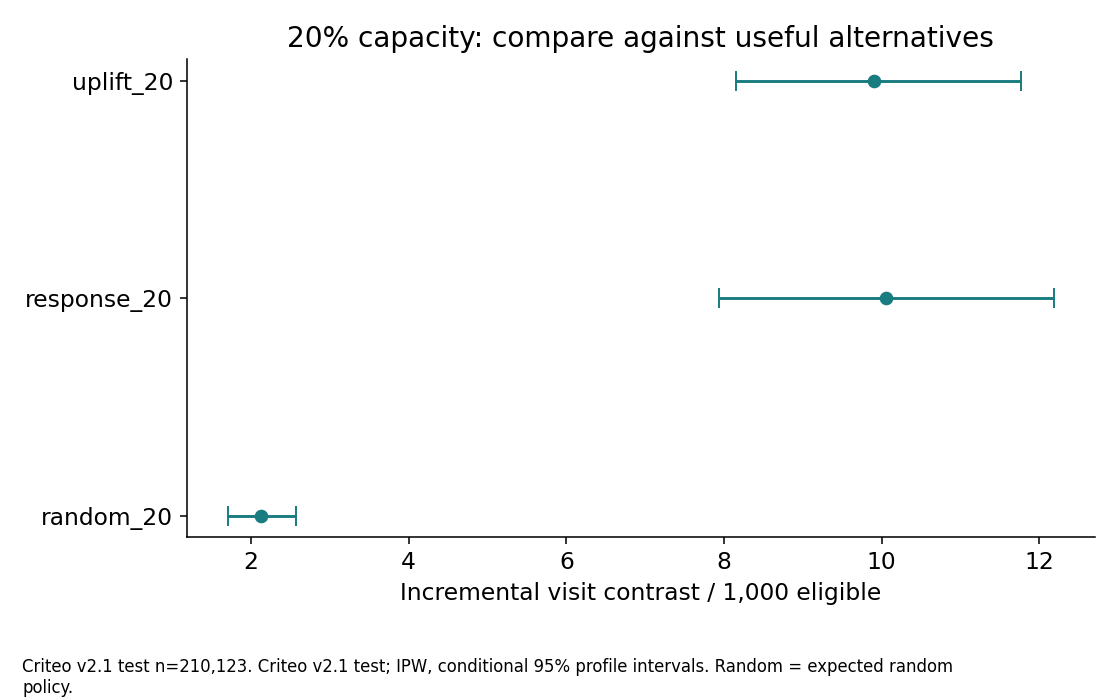

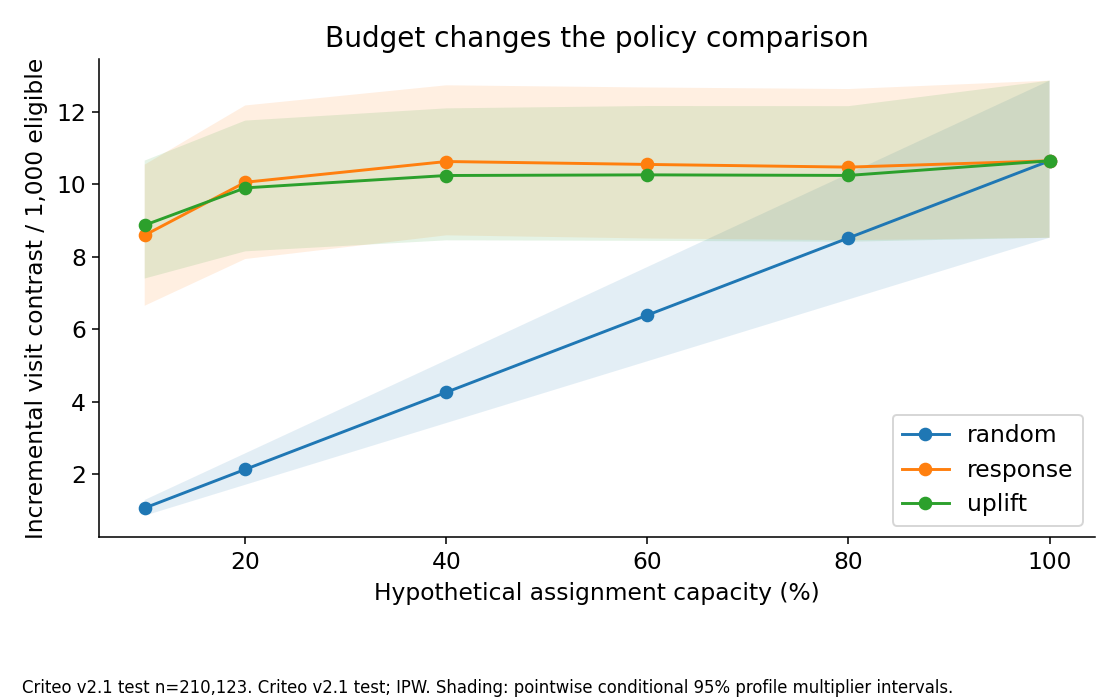

In [5]:
display(Image(filename=str(R/'figures/03_policy.png')))
display(Image(filename=str(R/'figures/02_capacity.png')))

## Robustness and miscalibration

Compare IPW to an augmented DR score, approximate published p=0.85 and covariate propensity. None repairs unknown publisher selection. Observed decile effects and predictions can disagree: good ranking is not calibrated individual effects.

,estimator,advantage_over_random,low,high
0,IPW,7.774497,6.325004,9.300803
1,DR,4.077607,2.896776,5.475876
2,IPW_p085,7.829588,6.383042,9.353546
3,IPW_covariate,6.057879,4.536252,7.702073


,decile,n,treated,control,mean_predicted_per_1000,observed_ipw_per_1000,low,high
0,1,21013,18306,2707,75.978635,88.752798,71.357133,104.338393
1,2,21013,17979,3034,9.043666,10.293310,2.189516,17.534971
2,3,21013,17843,3170,3.103392,2.991650,-0.657837,6.590755
3,4,21012,17832,3180,1.480378,0.426533,-3.145141,3.242397
4,5,21012,17768,3244,0.772136,0.067559,-1.647198,1.701795
5,6,21012,18131,2881,0.572942,0.108902,-1.104431,1.152391
6,7,21012,18061,2951,0.505177,-0.282844,-1.645321,0.748709
7,8,21012,17881,3131,0.406269,0.126548,-1.446759,1.404855
8,9,21012,17476,3536,-0.364288,1.239268,-2.443878,4.673900
9,10,21012,17798,3214,-19.447190,2.795142,-8.893623,15.155186


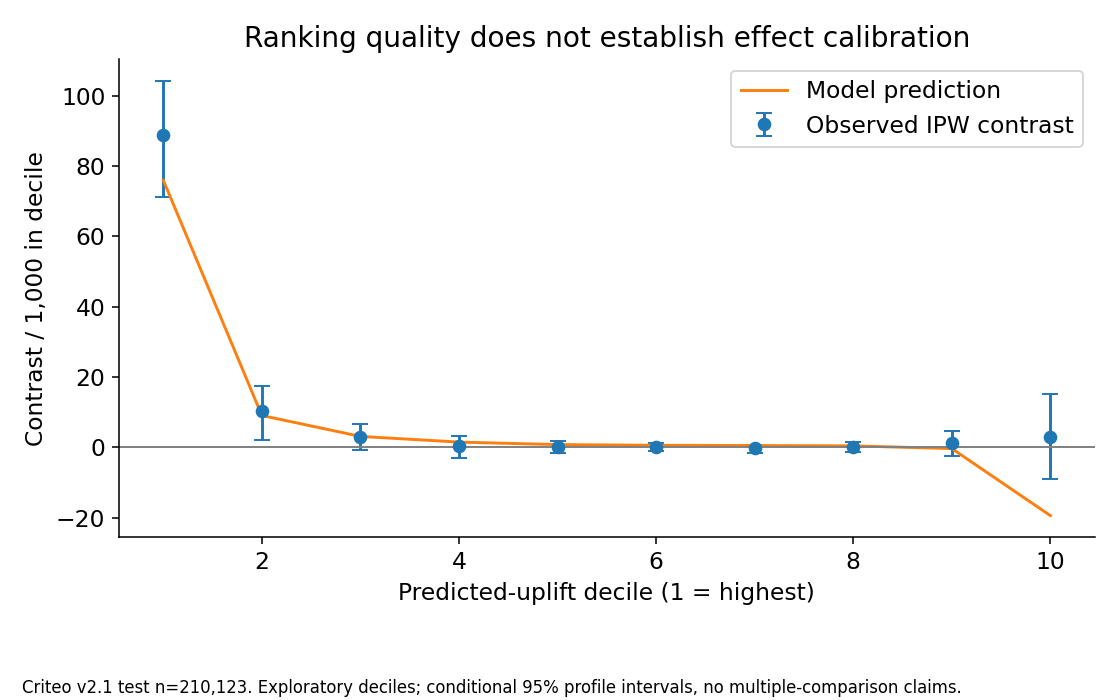

In [6]:
display(pd.read_csv(R/'sensitivity.csv'))
display(pd.read_csv(R/'deciles.csv'))
display(Image(filename=str(R/'figures/04_deciles.png')))

## Recompute the decision, then challenge it

A same-budget positive advantage can justify a follow-up experiment in the benchmark setting, not a carrier rollout. To transfer the method, collect randomized offer assignments, eligible pre-treatment features, actual costs and retention outcomes. Independently learn and evaluate a policy on those observations. No telecom effect is supplied by Criteo.

In [7]:
delta=((p.policy_uplift_20-.2)*p.ipw*1000).mean()
print(f'Frozen uplift-minus-random contrast: {delta:.3f} per 1,000 eligible')
print('Evidence limits: unknown selection, anonymous features, no dates, source-domain only.')

Frozen uplift-minus-random contrast: 7.774 per 1,000 eligible
Evidence limits: unknown selection, anonymous features, no dates, source-domain only.


## Ownership experiment

Before a new evaluation, copy the study to a new local experiment directory and change one declared scientific choice (sample hash seed, capacity, propensity or model class). Preserve this study and all held-out results. Do not repeatedly tune against this test. Read BUILDERS_GUIDE for a two-hour path and seven substantive daily exercises.